# Lagrangian turbulence: data and MGD model
Data: one velocity component of the DNS of Li et al. (2024). Model: run `turbulence_nested_M3_bicw_allmass_scat4` (B + Scat4), seed 900
(wavelet marginals on two Morlet banks, Q = 1 and Q = 3; fourth-order scattering coefficients; $L^6$ norm).
$\Theta$ = $\Theta_{\rm reg}$ at the last time step of the transport ($t \approx 1$), $\lambda = 3\cdot10^{-5}$;
unconstrained for now (the $L^6 < 0$ solve is still running): set `UNC = False` below once it is done.

Run on Jean Zay from `turbulence/`, after `python turbulence/talk_logp_generated.py` (GPU). Figures: `figures/talk/`.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
ROOT = Path.cwd()                                   # turbulence/
for p in ('codes', 'codes/filters', 'codes/potentials', 'data', 'turbulence', 'jets'):
    sys.path.insert(0, str(ROOT.parent / p))
import json
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
import talk_figures as tf
import run_comparison as rc
from logp_family_contrib import load_potentials
tf.set_output(ROOT / 'figures' / 'talk')          # every figure is also saved here as PNG

In [2]:
LABEL, SEED, LAM = 'turbulence_nested_M3_bicw_allmass_scat4', 900, 3e-5
UNC = False                                         # True: unconstrained Theta_reg; False: L_6<0 (when finished)
runs, missing = rc.load_runs({'model': LABEL}, seed=SEED)
assert not missing, missing
run = runs['model']
cfg = run['cfg']
x1 = rc.reference_data(cfg).numpy()                  # training data (n, T), standardized
xt = run['xt'].numpy()                               # generated signals
d = np.load(ROOT / 'figures' / 'data' / f'logp_C_{LABEL}_lam{LAM:g}{"_unc" if UNC else ""}.npz')                 # log p of the data
g = np.load(ROOT / 'figures' / 'data' / f'talk_logp_generated_{LABEL}.npz')              # log p of the generated
assert str(d['theta_desc']) == str(g['theta_desc']), (str(d['theta_desc']), str(g['theta_desc']))
assert UNC or str(d['theta_desc']).startswith('L_6<0'), d['theta_desc']
inc = np.abs(np.diff(x1, axis=1)).max(1)                                                 # same signals, same order
print('run config  :', cfg['config_name'])
print('n signals       : npz', len(d['TOTAL']), '| x1', len(x1), '| cfg n1', cfg['n1'], '| M', cfg['M'], '| x1 shape', x1.shape)
if len(d['TOTAL']) == len(x1):
    print('max increment   : max |npz - x1| =', float(np.abs(d['increment'] - inc).max()), '| relative', float((np.abs(d['increment'] - inc) / inc).max()))
assert len(d['TOTAL']) == len(x1) and np.allclose(d['increment'], inc, rtol=1e-3, atol=1e-5), 'npz does not match x1 (numbers printed above)'
theta = g['theta']
# independent runs (seeds): generated signals and data log p of each, for the error bands over seeds
SEEDS = [900, 901, 902, 903, 904]
tf.BAND = 'seeds'                                    # 'batch': min/max over batches of one run | 'seeds': mean ± std over SEEDS
xts = [xt]
for s in SEEDS[1:]:
    r_s, miss_s = rc.load_runs({'model': LABEL}, seed=s)
    assert not miss_s, (s, miss_s)
    xts.append(r_s['model']['xt'].numpy())
def _dfile(s):
    return ROOT / 'figures' / 'data' / f'logp_C_{LABEL}{"" if s == 900 else f"_seed{s}"}_lam{LAM:g}{"_unc" if UNC else ""}.npz'
DS = [np.load(_dfile(s)) for s in SEEDS if _dfile(s).exists()]
print(f'seeds with generated signals: {SEEDS} | seeds with data log p: {len(DS)}')
print('Theta:', d['theta_desc'])
print('data', x1.shape, '| generated', xt.shape)

Theta: L_6<0 constrained lam0.0005_ridge0.0001_moment_mask_neg0.01_NOTCONVERGED_20261023_224929.pt
data (10000, 256) | generated (10000, 256)


## Data signals with rare events
A signal is rare when its largest one-step increment $|x(t+1)-x(t)|$ (acceleration) is above the 95th percentile over the data, i.e. the top 5 % (`RARE_PCT`, next cell; the same in every figure of this notebook).
10 rare signals chosen at random.

In [ ]:
RARE_PCT = 95                                                                   # rare = top 5 % of signals, in every figure of this notebook
rare = d['increment'] > np.percentile(d['increment'], RARE_PCT)
idx = np.random.default_rng().choice(np.flatnonzero(rare), 10, replace=False)   # no seed: new examples each run
print('signals shown:', idx)
tf.plot_signals(x1[idx], 'data_rare_signals', color=tf.RARE)


## Increments at three lags: data vs generated
Increments $\delta_\tau x$ at $\tau/\tau_\eta$ = 20, 5, 1, data (left) against generated (right), as Li et al. Fig. 1b–d. Typical signals at 20 and 5, a rare signal by acceleration at 1; the largest increment at each lag is marked. Second figure: same layout, signals selected by $\log p$ (among the 5 % highest $-\log p$).

In [ ]:
from paper_figures_li import TAU_ETA
tau_eta = TAU_ETA / (cfg['subseries_len'] // cfg['target_len'])
# increments at three lags, data (left) vs generated (right), as Li et al. Fig. 1b-d: typical signals at tau/tau_eta = 20, 5;
# at tau/tau_eta = 1 a rare signal by acceleration (top 100 - RARE_PCT = 5 %); the largest increment at each lag is marked
tf.plot_rare_events(x1, xt, tau_eta, 'rare_events_data_vs_generated', tau_ratios=(20, 5, 1), window=40, rare_pct=RARE_PCT)
# same layout, signals selected by log p: among the 5 % highest -log p (isolated outliers beyond the cut dropped)
tf.plot_rare_events(x1, xt, tau_eta, 'rare_events_by_logp', tau_ratios=(20, 5, 1), window=40,
                    logp_data=d['TOTAL'], logp_model=g['logp'], logp_pct=100 - RARE_PCT)


## Three clean signals (Lagrangian)
Slide format: no axes, no $\tau$, no markers. One calm, one medium, one agitated signal, picked by acceleration (largest one-step increment) at the 20th, 70th and 97th percentile over the data; same vertical scale. `seed=None`: new signals at every run (indices printed); `sharey=False` lets each one fill its panel.
Each figure is also saved with axes (`*_axes_k.png`, same signals): $x/\sigma(x)$ on the vertical axis (amplitude in standard deviations), time on the horizontal axis.

In [ ]:
tf.plot_clean_signals(x1, 'clean_lagrangian', accel_pcts=(20, 70, 97))   # + clean_lagrangian_axes_1..3.png

## Four data and four generated signals, one per category
Two steps, a spike and a packet: clearest examples (`sample_categories/categorize.py`). The generated labels were made on the samples of **seed 904**, so the right column uses seed 904.

In [ ]:
cats = json.load(open(ROOT / 'sample_categories' / 'categories_bicw_allmass_scat4_seed904.json'))
r904, miss904 = rc.load_runs({'model': LABEL}, seed=904)
assert not miss904, miss904
assert Path(cats['model_samples']).stem == r904['model']['config'], (cats['model_samples'], r904['model']['config'])
xt904 = r904['model']['xt'].numpy()
PICKS = [('step', 0), ('step', 1), ('spike', 0), ('packet', 0)]      # (category, rank in its 'clearest' list), one row each
tf.plot_signal_pairs(x1, xt904, [cats['clearest'][c]['data'][r] for c, r in PICKS],
                     [cats['clearest'][c]['model'][r] for c, r in PICKS], 'signals_by_category', tau_eta=tau_eta)

## Data and generated signals, side by side
4 random data signals (left, black) next to 4 random generated ones (right, blue), same vertical scale.

In [4]:
def compare_signals(data, gen, n=4, seed=None):
    """n random data signals (left, black) next to n random generated ones (right, blue), same y-scale
    everywhere. seed=None: different examples at every call; pass the printed seed to get a set back."""
    seed = np.random.SeedSequence().entropy % 10**6 if seed is None else seed
    rng = np.random.default_rng(seed)
    i_d = rng.choice(len(data), n, replace=False)
    i_g = rng.choice(len(gen), n, replace=False)
    d, g = np.asarray(data)[i_d], np.asarray(gen)[i_g]
    lim = 1.05 * max(np.abs(d).max(), np.abs(g).max())
    fig, axes = plt.subplots(n, 2, figsize=(5, 1.3 * n + 0.8), sharex=True, sharey=True)
    for k in range(n):
        axes[k, 0].plot(d[k], color=tf.DATA, lw=1.1)
        axes[k, 1].plot(g[k], color=tf.MODEL, lw=1.1)
        for ax in axes[k]:
            ax.set_ylim(-lim, lim)
            ax.grid(False)
            ax.tick_params(labelsize=9)
    axes[0, 0].set_title('data')
    axes[0, 1].set_title('generated')
    for ax in axes[-1]:
        ax.set_xlabel('time (samples)')
    fig.subplots_adjust(hspace=0.15, wspace=0.05)
    print(f'seed {seed} | data indices {i_d.tolist()} | generated indices {i_g.tolist()}')
    display(fig)
    plt.close(fig)

seed 584030 | data indices [1926, 9768, 3174, 8999] | generated indices [4445, 8945, 9840, 723]


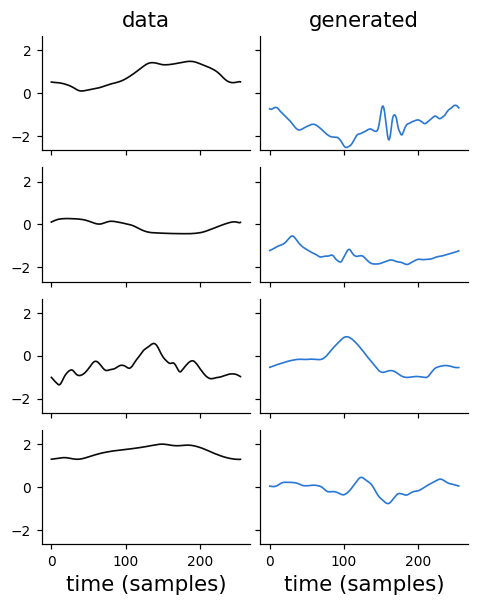

In [5]:
compare_signals(x1, xt)

## Wavelet coefficients of the data, per scale
Real part of the Morlet wavelet coefficients, one panel per scale $j$, divided by their standard deviation.
Dashed: standard Gaussian.

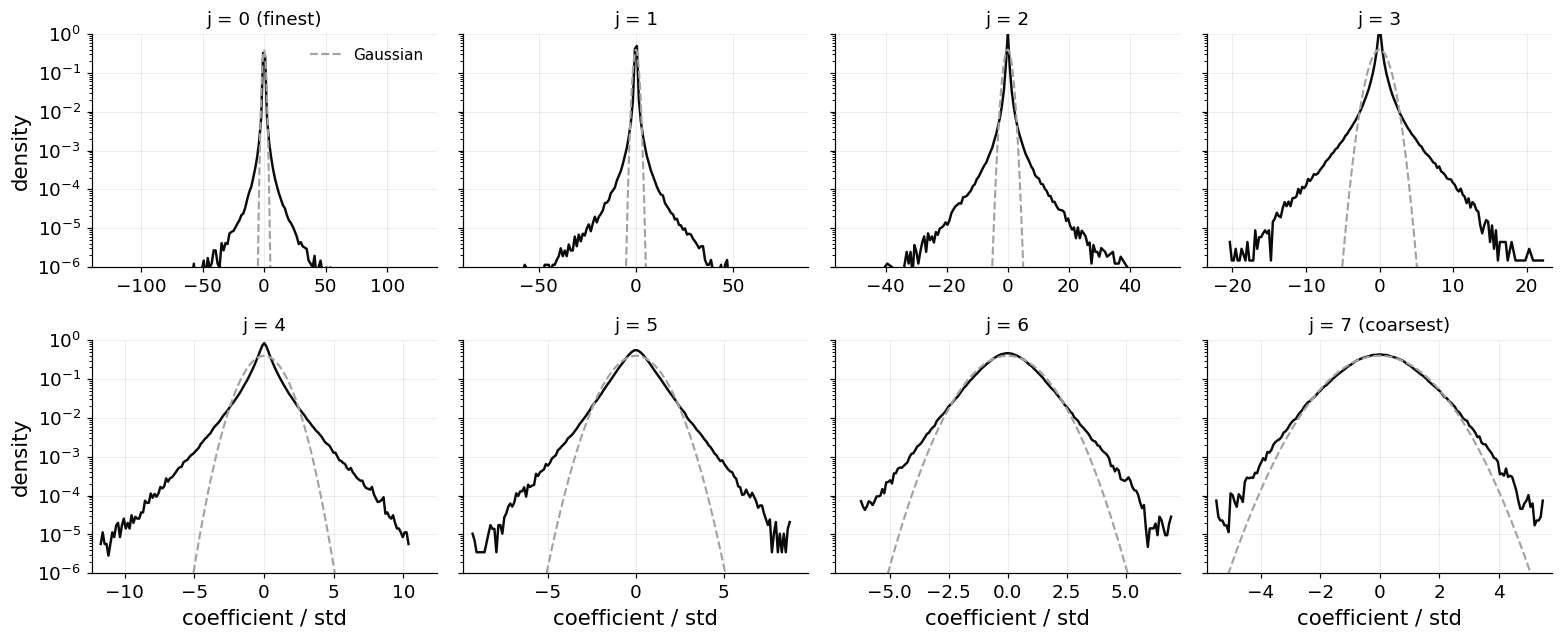

In [6]:
tf.plot_wavelet_histograms(x1, int(cfg['J']), 'data_wavelet_histograms')
tf.plot_wavelet_histograms(x1, int(cfg['J']), 'wavelet_hist_Q3', Q=int(cfg['Q']), ncol=6)      # Q = 3 bank, 6 panels per row

## One signal and its wavelet transform at every scale
Data signal #2857 (a 'packet': oscillatory burst) and its Morlet wavelet transform (Q = 1, scales $2^j$). Each row: real part (orange) and imaginary part (grey) of the wavelet coefficients, scaled to its own maximum.

In [ ]:
i_ev = cats['clearest']['packet']['data'][5]          # = 2857 ("D #2857" in sample_categories.ipynb)
assert i_ev == 2857, i_ev
tf.plot_wavelet_stack(x1[i_ev], int(cfg['J']), 'wavelet_stack_Q1', Q=1)

## The Morlet wavelets of the model
The filters used by the model (M = 256, J = 8), Q = 1 and Q = 3. For each Q: one wavelet at scale $2^3$ (centre $\omega = \pi/8$ rad per sample, period 16 samples) in time, real part (orange) and imaginary part (grey), divided by its maximum modulus; then its Fourier transform. Time: each Q has its own window (cut where the wavelet falls below 1 % of its maximum). Fourier: the same window $0 \le \omega \le 3\pi/8$ for both. Each figure carries the width (2 × rms width of $|\psi(t)|^2$, resp. $|\hat\psi(\omega)|^2$). Last: all the wavelets of the bank in Fourier space (log $\omega$, one dot per frequency of the 256-point grid). Does not need the run.

In [ ]:
# the model's Morlet wavelets (filters_bank.return_Filters, M = 256, J = 8), Q = 1 and Q = 3
for Q in (1, int(cfg['Q'])):
    tf.plot_wavelet_single(int(cfg['M']), int(cfg['J']), Q, f'wavelet_Q{Q}', omega_max=3 * np.pi / 8)   # _time, _fourier
    tf.plot_wavelet_tiling(int(cfg['M']), int(cfg['J']), Q, f'tiling_Q{Q}')                             # all wavelets in Fourier

## Increments along time (as Li et al., Fig. 1b–d)
The signal $x$ and its increments $\delta_\tau x(t) = x(t+\tau) - x(t)$ at $\tau/\tau_\eta$ = 20, 5, 1, against $t/\tau_\eta$:
8 random signals of ~55 $\tau_\eta$ laid end to end (breaks between signals). Each row is divided by the standard
deviation of the data increments at that $\tau$, for data and model alike.


seed 120078: 8 signals of 55 tau_eta each, laid end to end


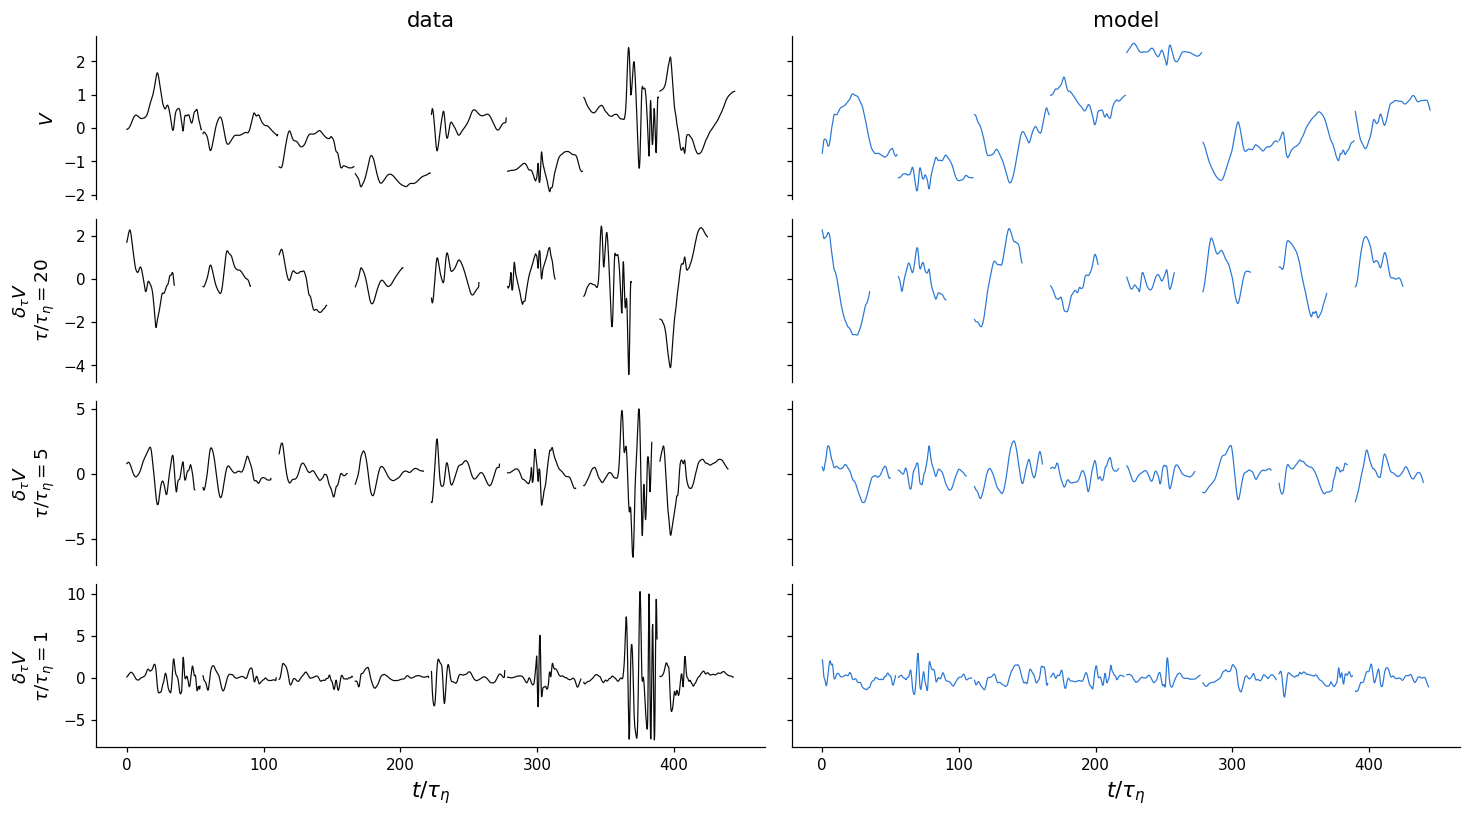

In [15]:
tf.plot_increment_trajectories(x1, xt, tau_eta, 'li_increment_trajectories', n_windows=8)

## Statistics of Li et al. (2024): data and model
Increments $\delta_\tau x = x(t+\tau) - x(t)$, structure functions $S_p(\tau) = \langle (\delta_\tau x)^p \rangle$,
flatness $F_p = S_p / S_2^{p/2}$, local exponents $\zeta_p = d\log S_p / d\log S_2$.
Bands (every figure here, increment PDFs included): data = min–max over 10 disjoint batches of $10^3$ signals; model = mean ± std over the 5 seeds (`tf.BAND = 'seeds'`).
$\tau_\eta$ = 9.33 samples of the DNS (Li et al., Table 1), i.e. 4.67 samples here (signals coarse-grained by 2).
Lags up to half the signal length (the signals are periodized windows).

In [ ]:
from paper_figures_li import TAU_ETA
tau_eta = TAU_ETA / (cfg['subseries_len'] // cfg['target_len'])
max_lag = x1.shape[-1] // 2
xm = xts if tf.BAND == 'seeds' else xt                      # band over seeds needs one array per seed
tf.plot_increment_pdfs(x1, xm, tau_eta, 'li_increment_pdfs')
tf.plot_structure_functions(x1, xm, tau_eta, max_lag, 'li_structure_functions')
tf.plot_flatness(x1, xm, tau_eta, max_lag, 'li_flatness')
tf.plot_local_exponents(x1, xm, tau_eta, max_lag, 'li_local_exponents')

## Statistics of the draft's Fig. 6: data and model
Same formulas as the draft (`turbulence/paper_figs_ensemble.curves`), talk style; 3 figures of 3 panels.
Skewness of the power increments $(x(t+\tau) - x(t))\,x(t)$ (`skew_mode='power'`, as in the draft).
Bands: `tf.BAND` (`'seeds'`: mean ± std over the seeds; `'batch'`: min / max over 10 batches of one run).

In [ ]:
st6 = tf.fig6_stats(x1, xm, tau_star=20, skew_mode='power')        # computed once; xm = xts (seeds) or xt (batch)
tf.plot_fig6(st6, 'fig6_lagrangian', tau_eta=tau_eta)                 # lags in tau_eta; groups=('sf',) etc. for one panel

## Distribution of −log p over the data
$-\log_{10} p(x)/d$ with $d = 256$, $-\log p(x) = -\Theta \cdot \phi(x)$ up to a constant, for the training signals; the seeds pooled, each centred on its own mean, so the plot is centred at zero (rare signals on the right). Unit area.
Red: rare signals (top 5 % in acceleration, definition written under the plot).

In [ ]:
NOTE = ('Rare signal: its largest one-step increment, $\\mathrm{max}_t\\, |x(t+1) - x(t)|$ (acceleration),\n'
        f'is above the {RARE_PCT}th percentile of this quantity over all data signals.')
dseeds = DS if len(DS) > 1 else [d]                                        # data log p of every seed (5 if all files exist)
tot = np.concatenate([ds['TOTAL'] - ds['TOTAL'].mean() for ds in dseeds])   # each seed centred on its own mean (log p: constant free)
rare_all = np.concatenate([ds['increment'] > np.percentile(ds['increment'], RARE_PCT) for ds in dseeds])
print(f'{len(dseeds)} seed(s) pooled, {len(tot)} signals')
tf.plot_logp_histogram(tot, 'neglogp_data', rare=rare_all, rare_label=f'rare signals (top {100 - RARE_PCT} %)',
                       min_freq=1e-4, note=NOTE)                     # -log10 p / d; tail cut as the ranked signals

In [ ]:
loc, scale = tf.plot_logp_gumbel(tot, 'neglogp_data_gumbel', d=x1.shape[1], min_freq=1e-4)   # Gumbel fit, S&P style

## −log p for a Gaussian with the turbulence spectrum
Training signals: 10000 draws of the stationary Gaussian whose power spectrum is the turbulence spectrum (averaged over the
training windows), not white noise. Model: MGD with second-order scattering only (Q = 1), run `turbulence_gauss_spectrum`,
$\Theta_{\rm reg}$ with $\lambda = 5\cdot10^{-4}$. Here the true $-\log p$ is known exactly.
Left: exact (black) and MGD (blue) $-\log p$ of the training signals, each relative to the mean over its own law's samples.
Right: MGD against exact, one point per signal. Needs `python turbulence/logp_gauss_scat2.py ... --outdir turbulence/saved_results/gauss_spectrum_logp` (gauss_spectrum/README.md).

In [ ]:
tf.plot_logp_gaussian(ROOT / 'saved_results' / 'gauss_spectrum_logp' / 'all_seeds.npz', 'logp_gauss_spectrum')

## Signals ranked by −log p, from the most typical to the rarest
Left: $-\log p$ of all the signals, relative to the median. Arrows: 10 evenly spaced values from the lowest (most typical) to the
highest (rarest) $-\log p$; right: the signal closest to each value, same colour, $-\log p$ on top.
First figure: the generated signals, with the log p of the model that generated them. Second: the same for the data signals (training set), with the log p the model gives them.

ranked signals: support capped at freq >= 0.0001 -> [-423.4, +234.3] nats; 11 below, 0 above of 10000 signals left out


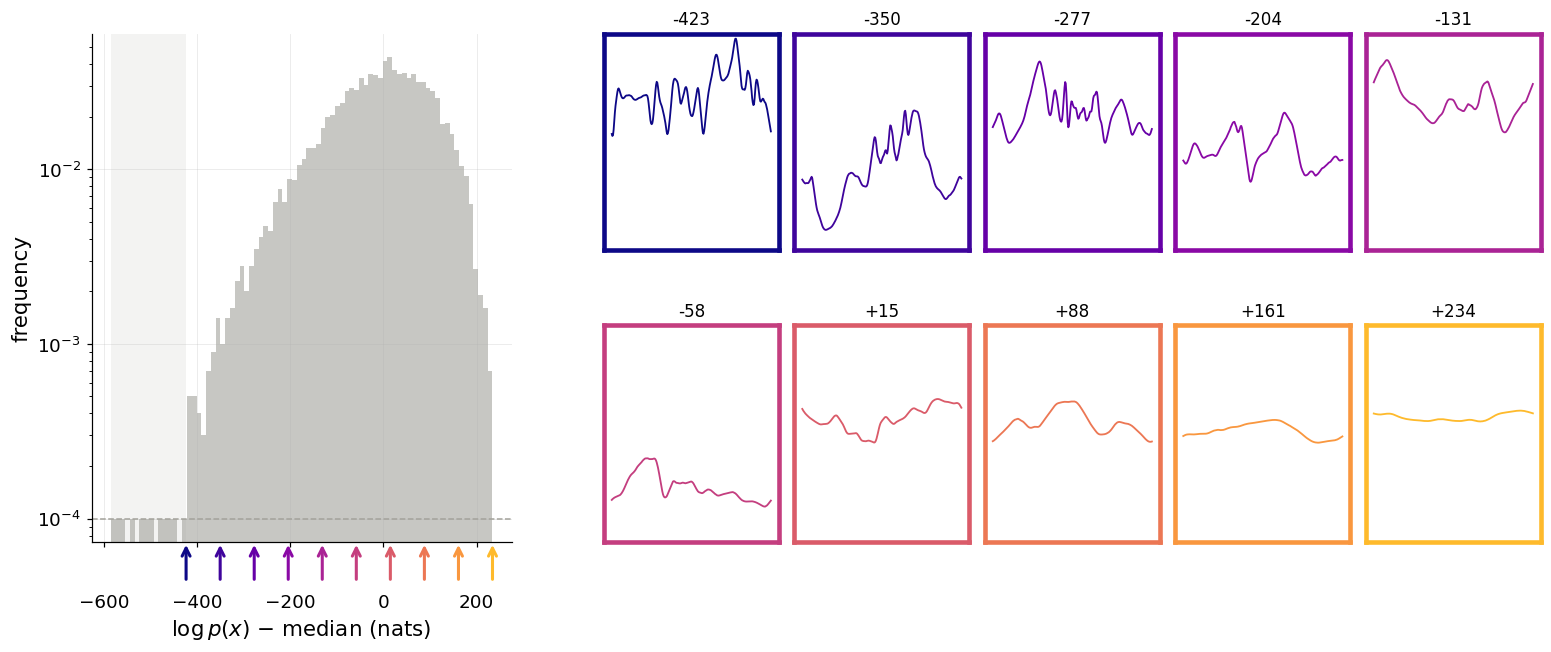

In [11]:
tf.plot_ranked_signals(xt, g['logp'], 'generated_ranked', n=10, min_freq=1e-4, random=True)
tf.plot_ranked_signals(x1, d['TOTAL'], 'data_ranked', n=10, min_freq=1e-4)           # the same for the data

## Number of statistics in the model
Per potential family, as used in the run (after removing duplicate filters and empty windows).

In [10]:
# number of statistics per family
from logp_family_contrib import phi_matrix
exp = rc._find_exp_dir(ROOT, run['config'])
pots = load_potentials(exp, cfg, 'cpu')
xs = torch.as_tensor(x1[:200]).reshape(200, 1, -1).float()
n_stats = tf.count_statistics(pots, xs, theta, Q=cfg['Q'])
n_stats.to_csv(ROOT / 'figures' / 'talk' / 'number_of_statistics.csv')
display(n_stats)

# diagnostic (does not stop the notebook): saved log p vs recomputed here, per family
from check_potentials import theta_column_map
phi = phi_matrix(pots, xs)
for name, (a, w) in theta_column_map(pots, len(theta)).items():
    rec, sav = phi[:, a:a + w] @ theta[a:a + w], d[name][:200]
    print(f'{name:40s} max|diff| {np.abs(rec - sav).max():10.4g}   std across signals {sav.std():10.4g}')
print(f'{"TOTAL":40s} max|diff| {np.abs(phi @ theta - d["TOTAL"][:200]).max():10.4g}   std {d["TOTAL"][:200].std():.4g}')

[deduplicate_filters] filters_Q: 25 -> 22 channels for channel-list potentials (dropped duplicates [21, 22, 23], tol=1e-08)


,statistics,with Θ ≠ 0 at t = 1
family,,
L⁶ norm,9,9
"Marginals (Morlet, Q = 3)",107,107
"Marginals (Morlet, Q = 1)",44,44
Scattering 4 (Re),84,84
Scattering 4 (Im),56,56
total,300,300


L_6                                      max|diff|  1.591e-06   std across signals     0.7577
Scalar_psi_gaussianK                     max|diff|   0.005719   std across signals      407.9
Scalar_morlet_gaussianK                  max|diff|   0.002043   std across signals      382.4
Scattering_Fourth_Order_Mod2_Real_Q1     max|diff|  1.111e-05   std across signals       3.82
Scattering_Fourth_Order_Mod2_Imag_Q1     max|diff|  5.904e-06   std across signals     0.6459
TOTAL                                    max|diff|    0.00563   std 131


## Contribution of each potential family to −log p
For each data signal, $C_F(x) = -\Theta_F \cdot \phi_F(x)$, and $-\log p(x) = \sum_F C_F(x)$ + constant.
Top: mean over signals (its zero is arbitrary: a constant added to $\phi_F$ changes it, not $p$).
Middle: standard deviation across signals. Bottom: the same divided by the standard deviation of $-\log p$.

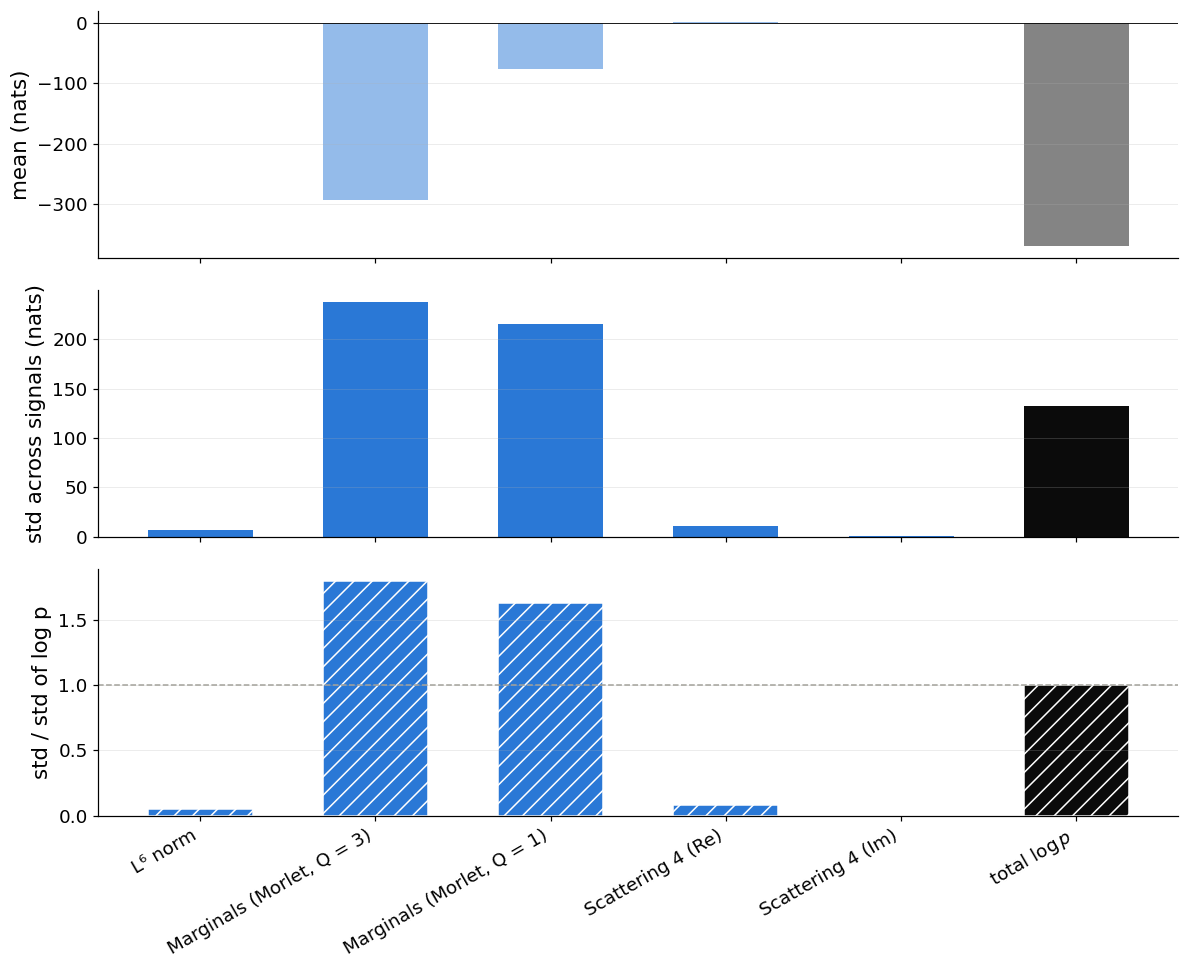

In [13]:
fams = [k for k in d.files if k not in ('increment', 'theta_desc', 'TOTAL')] + ['TOTAL']
per_seed = DS if (tf.BAND == 'seeds' and len(DS) > 1) else [d]          # error bars = std over seeds (ddof = 1)
tf.plot_energy_bars({k: np.stack([ds[k] for ds in per_seed]) for k in fams}, 'logp_per_family', Q=cfg['Q'])

## Table: first-order KL per dimension of each category of statistics (generated signals)
**Quantity.** $\ln p = \Theta\cdot\phi$ + constant (the model is $p\propto e^{+\Theta\cdot\phi}$), split into categories $k$: scalar multiscale (marginals, scattering orders 1–2) · order 3 Re / Im (none in this model) · order 4 Re / Im. For the category $k$, $\mathrm{KL}_k \simeq \tfrac12\mathrm{Var}(\ln p_k)$ in nats (first order of $D_k = \log E_p\,e^{-(C_k-m_k)}$, $C_k=\Theta_k\cdot\phi_k$); per dimension and in $\log_{10}$ units (digits per dimension, the units of the $u=-\log_{10}p/d$ axis of the histograms): **Var$(\ln p_k)/(2d\ln 10)$**, $d = 256$. A KL changes unit linearly (÷ ln 10), a variance would change by $\ln^2 10$; $\mathrm{Var}(\ln p_k)$ grows like $d$, so dividing by $d$ makes it intensive.
**Entries.** Number of moments; value = mean $\pm$ std **over the 5 seeds**, error to one significant digit (two if it starts with 1), each cell with its own power of ten. Evaluated on the **generated** signals (as in the S&P table, where the data is a single series).
**Shaded column** (a different quantity): **std$(-\log p)$** = std of the total $u=-\log_{10}p/d$ over the signals, in digits per dimension: the width of the histogram (it falls like $1/\sqrt d$). It includes the confinement term, which has its own table.
**Reading.** Contributions are correlated, so the entries do not add up to the total (a category can fluctuate more than the total when families anticorrelate). The constant of $\log p$ drops out of a variance. Needs `python turbulence/talk_logp_generated.py --seed S` for each seed (GPU). Saved as `kl_table_lagrangian.csv`, read by talk_jets.ipynb. All tables, generated and dataset signals, in one go: `python codes/make_kl_tables.py`.

In [ ]:
widths = {f: w for f, (a, w) in theta_column_map(pots, len(theta)).items()}
D_SIG = int(cfg['M'])                                                            # length of the signals (256)
# per-family log p of the GENERATED signals, one file per seed (python turbulence/talk_logp_generated.py --seed S ...)
def _gfile(s):
    return ROOT / 'figures' / 'data' / f'talk_logp_generated_{LABEL}{"" if s == 900 else f"_seed{s}"}.npz'
missing_g = [s for s in SEEDS if not _gfile(s).exists()]
assert not missing_g, f'no generated per-family log p for seeds {missing_g}: run talk_logp_generated.py'
GS = [np.load(_gfile(s)) for s in SEEDS]
assert all(set(fams) <= set(gs.files) for gs in GS), 'files without the per-family keys: rerun talk_logp_generated.py'
assert all(str(gs['theta_desc']) == str(d['theta_desc']) for gs in GS[:1]), 'Theta differs from the data log p'
K_lag = tf.kl_table({k: np.stack([gs[k] for gs in GS]) for k in fams}, widths, D_SIG, 'kl_table_lagrangian')
display(K_lag)
tf.plot_kl_table_single(K_lag, 'kl_table_lagrangian', 'Lagrangian')              # only the categories in the model (no order 3)

## Outliers of the generated log p
Signals below the support cut of the ranked-signals plot (frequency per bin < `MIN_FREQ`). How many, what they look like,
and what drives their low log p. Needs `pots` and `theta` from the "number of statistics" cell above.

In [ ]:
MIN_FREQ, BINS = 1e-4, 80                                  # same as tf.plot_ranked_signals(..., min_freq=MIN_FREQ)

# 1. how many (generated and data, each with its own median and its own cut)
sup = {}
for name, lp in (('generated', g['logp']), ('data', d['TOTAL'])):
    v = np.asarray(lp, float) - np.median(lp)
    lo, hi, *_ = tf.logp_support(v, BINS, MIN_FREQ)
    sup[name] = (v, lo, hi)
    print(f'{name:9s} n = {len(v)} | support [{lo:+.1f}, {hi:+.1f}] | below {(v < lo).sum()} ({(v < lo).mean():.1e}) | above {(v > hi).sum()}')
vg, lo_g, hi_g = sup['generated']
out = np.flatnonzero(vg < lo_g)
out = out[np.argsort(vg[out])]                              # rarest first
assert len(out), 'no generated outlier below the cut'
print('generated outliers (index: log p - median):', {int(i): round(float(vg[i]), 1) for i in out})

# 2. what they look like (labelled with -log p - median, as every figure)
tf.plot_signals(xt[out[:8]], 'generated_outliers', color=tf.MODEL, row_labels=[f'{-vg[i]:+.0f}' for i in out[:8]], labels_header=r'$-\log p$')

# 3. size of the events: largest one-step increment and largest |x|, as a percentile of the DATA, vs typical generated signals
rng = np.random.default_rng(0)
typ = rng.choice(np.setdiff1d(np.arange(len(xt)), out), 200, replace=False)
inc_g = np.abs(np.diff(xt, axis=1)).max(1)
pct = lambda a, ref: 100 * (ref[None, :] < np.asarray(a)[:, None]).mean(1)
amp_d = np.abs(x1).max(1)
tab = pd.DataFrame({'log p': vg[out], 'max |increment|': inc_g[out], 'pct of data increments': pct(inc_g[out], d['increment']),
                    'max |x|': np.abs(xt[out]).max(1), 'pct of data max|x|': pct(np.abs(xt[out]).max(1), amp_d)}, index=out)
print(f'typical generated (median of 200): max|increment| {np.median(inc_g[typ]):.2f} '
      f'(pct {np.median(pct(inc_g[typ], d["increment"])):.0f}), max|x| {np.median(np.abs(xt[typ]).max(1)):.2f}')
print(f'data: max|increment| 99.9th pct {np.percentile(d["increment"], 99.9):.2f}, largest {d["increment"].max():.2f}; largest max|x| {amp_d.max():.2f}')
display(tab.round(2))

# 4. which family of statistics makes them rare: contribution of each family, outliers minus typical, in std of typical
sel = np.concatenate([out, typ])
phi = phi_matrix(pots, torch.as_tensor(xt[sel]).reshape(len(sel), 1, -1).float())
rows = {}
for name, (a, w) in theta_column_map(pots, len(theta)).items():
    c = phi[:, a:a + w] @ theta[a:a + w]
    rows[name] = (c[:len(out)].mean() - c[len(out):].mean()) / c[len(out):].std()
fam = pd.Series(rows, name='(outliers - typical) / std typical').sort_values()
print('total log p:', round(float((phi @ theta)[:len(out)].mean() - (phi @ theta)[len(out):].mean()), 1), 'nats (mean outliers - mean typical)')
display(fam.round(2).to_frame())

# 5. copies of training signals? distance to the nearest data signal, outliers vs typical
nn = torch.cdist(torch.as_tensor(xt[sel]).float(), torch.as_tensor(x1).float()).min(1).values.numpy()
print(f'distance to nearest data signal: outliers median {np.median(nn[:len(out)]):.2f} | typical median {np.median(nn[len(out):]):.2f} '
      f'| data-to-data nearest (200 signals) {np.median(torch.cdist(torch.as_tensor(x1[:200]).float(), torch.as_tensor(x1[200:]).float()).min(1).values.numpy()):.2f}')
